# Football Managerial Decision Analytics — Chapter 04
## Starting XI and substitution decision support

> **Data.** StatsBomb Open Data (https://github.com/hudl/open-data), provided by StatsBomb / Hudl, used for educational, non-commercial research. Raw data are downloaded from the official repository at run time and are not redistributed here. Every figure carries its chart ID from `docs/VISUALIZATION_CATALOGUE.md`.

This notebook is one chapter of the research record. All logic lives in the shared `src/` package; the cells call it. The same charts are available interactively in the Streamlit dashboard (`streamlit run app.py`).

In [1]:
# Setup — locate the repository, import the shared package, load the workspace
import os, sys, time
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "workspace.py").exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from src.reporting.notebook_tools import (catalogue, explorer, implication, interpret, limitation, show, start,
                                          timed, timings)

pd.set_option("display.max_columns", 40, "display.width", 200, "display.float_format", "{:.3f}".format)
RUN_ADVANCED_GALLERY = True   # heavier, optional sections; the core story does not depend on them
SEED = 42                             # every resampling and model step takes this seed explicitly

ws = start(seed=SEED)                 # first run downloads and parses; later runs read the processed cache
B, T, FOCUS = ws.bundle, ws.tables, ws.focus
tm = ws.team_matches()                # the focus team's matches in date order
print(f"Advanced sections: {'on' if RUN_ADVANCED_GALLERY else 'off'} · Python {sys.version.split()[0]} · pandas {pd.__version__}")

**Workspace ready in 2.6s** (processed cache) · 1. Bundesliga 2023/2024 · 34 matches · 137,765 events · focus team **Bayer Leverkusen** · figures: static PNG (FMA_STATIC=1) · seed 42

Advanced sections: on · Python 3.10.11 · pandas 2.1.4


## F · Starting XI decision support

**Research question.** Which eleven does the evidence available *before* a match shortlist for a formation, why
is each player in it, and how sensitive is that to the weights?

**Data and method.** Candidates are players seen in recent match-day squads before the decision point. Each
candidate–slot score is

`(0.40·role fit + 0.20·recent form + 0.15·evidence volume + 0.15·minutes-based exposure + 0.10·continuity) × position compatibility`

with components on 0–100. Players are assigned to slots with the Hungarian algorithm under hard constraints
(eleven distinct players, one goalkeeper, eligibility, squad membership). **It is a transparent heuristic:
"best" means best under these weights and constraints.**

Decision point: before 03 Dec 2023: Bayer Leverkusen 1-1 Borussia Dortmund · formation 3-4-2-1
Pool: matchday squad of match 3895158 (2023-12-03)


,role_fit,recent_form,sample_reliability,workload_suitability,lineup_continuity
0,0.400,0.200,0.150,0.150,0.100


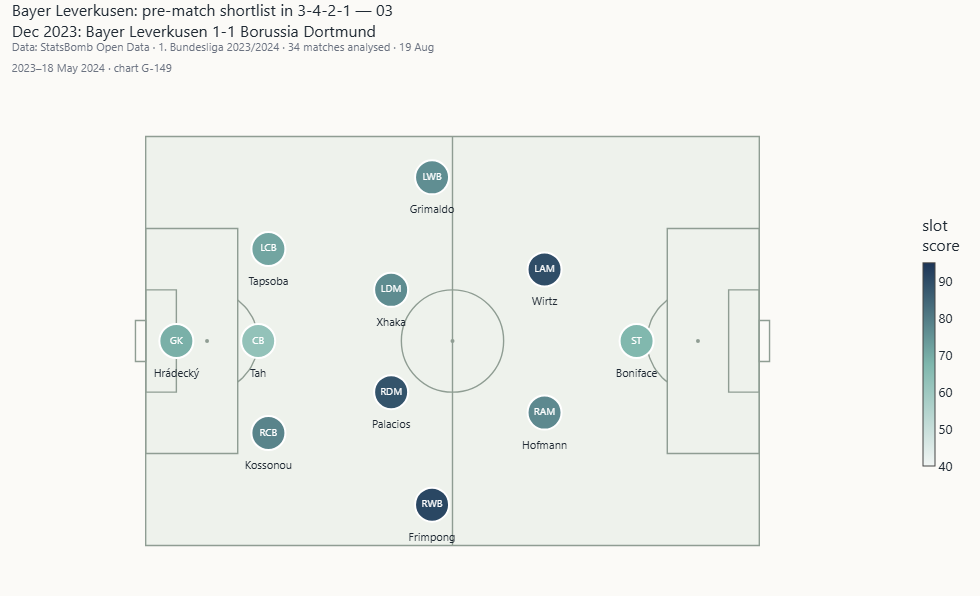

`G-149` Starting XI pitch diagram · *Method:* Hungarian assignment of candidates to formation slots. · *Caveat:* Best under the stated scoring model and constraints — a shortlist, not the optimal XI.

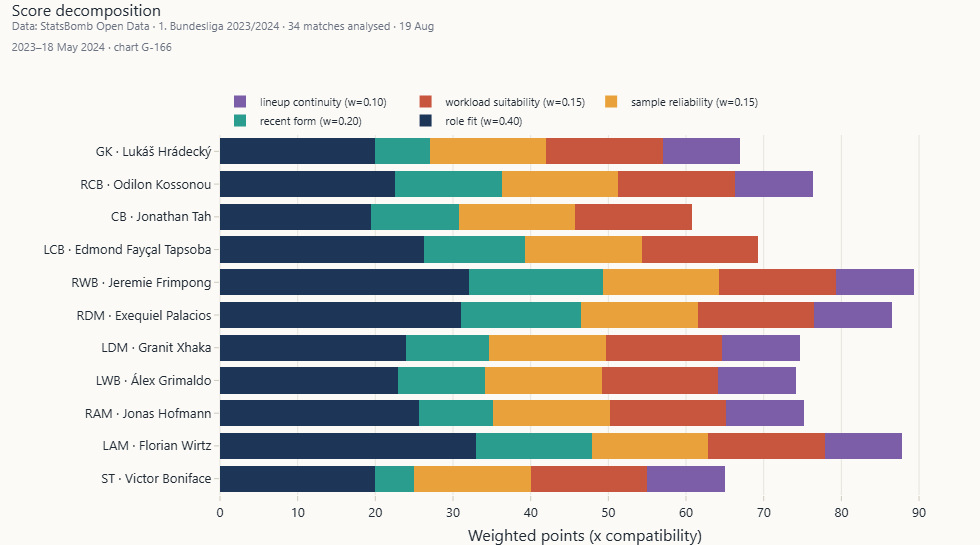

`G-166` Starting XI score component breakdown · *Method:* Weighted components per pick.

,slot,player_name,primary_role,compatibility,role_fit,recent_form,sample_reliability,workload_suitability,lineup_continuity,score,coverage_label
0,GK,Lukáš Hrádecký,GK,1.000,50.000,35.000,100.000,100.000,100.000,69.000,high data coverage
1,RCB,Odilon Kossonou,CB,1.000,56.400,68.600,100.000,100.000,100.000,78.300,high data coverage
2,CB,Jonathan Tah,CB,1.000,48.600,56.400,100.000,100.000,0.000,62.700,high data coverage
3,LCB,Edmond Fayçal Tapsoba,CB,1.000,65.700,65.000,100.000,100.000,0.000,71.300,high data coverage
4,RWB,Jeremie Frimpong,WB,1.000,80.000,86.400,100.000,100.000,100.000,91.300,high data coverage
5,RDM,Exequiel Palacios,DM,1.000,77.500,77.500,100.000,100.000,100.000,88.500,high data coverage
6,LDM,Granit Xhaka,DM,1.000,60.000,53.300,100.000,100.000,100.000,76.700,high data coverage
7,LWB,Álex Grimaldo,WB,1.000,57.100,56.400,100.000,100.000,100.000,76.100,high data coverage
8,RAM,Jonas Hofmann,AM,1.000,64.200,47.500,100.000,100.000,100.000,77.200,high data coverage
9,LAM,Florian Wirtz,AM,1.000,82.500,74.200,100.000,100.000,100.000,89.800,high data coverage


Optimiser warnings: ['Thin depth at GK: 1 natural candidate(s).']


In [2]:
from src.analytics import lineup_optimizer as xi
mid = ws.default_match()
p = ws.params()
ctx = ws.xi_context(FOCUS, mid)
res = ws.xi_result(FOCUS, mid, p.formation)
print(f"Decision point: before {ws.match_label(mid)} · formation {p.formation}")
print("Pool:", ctx.pool_description)
display(pd.DataFrame([B.config.xi_score_weights]))
show("G-149", ws, match_id=mid)
show("G-166", ws, match_id=mid)
display(res.lineup[["slot", "player_name", "primary_role", "compatibility", "role_fit", "recent_form", "sample_reliability",
                    "workload_suitability", "lineup_continuity", "score", "coverage_label"]].round(1))
print("Optimiser warnings:", res.warnings or "none")

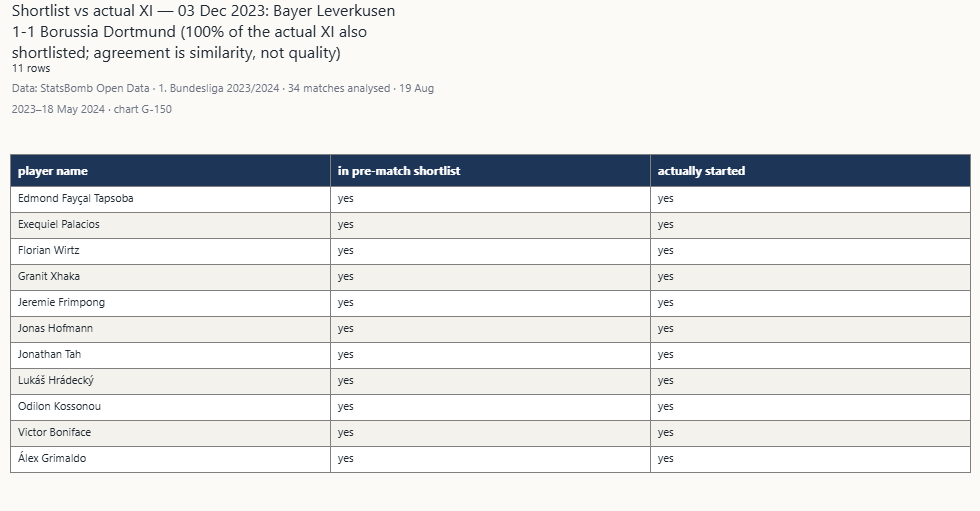

`G-150` Actual XI versus shortlisted XI · *Method:* Overlap table with the share of the actual XI also shortlisted. · *Caveat:* Agreement measures similarity, not which choice was better.

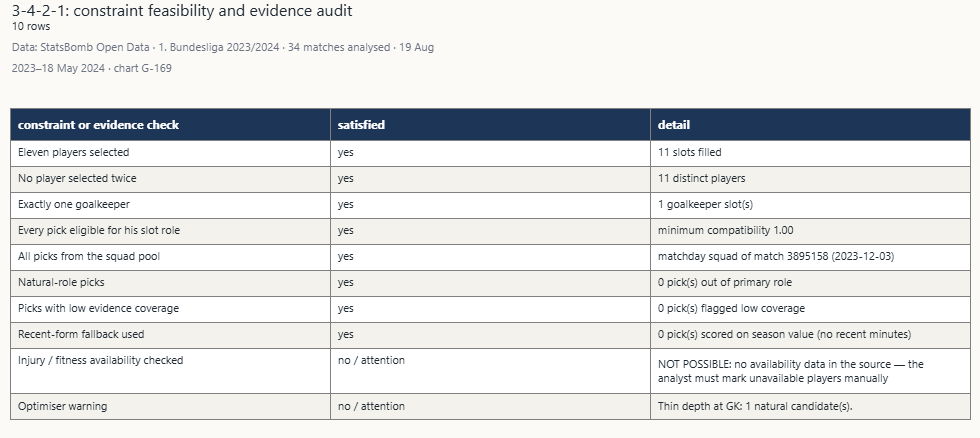

`G-169` Constraint feasibility audit · *Method:* Checklist of constraints and evidence gaps.

**Interpretation.** 100% of the players who actually started are in the shortlist. Shortlisted but not selected: none; selected but not shortlisted: none.

**Limitation.** Agreement measures similarity to the manager's choice, not whether either was better. The source has no injury, fitness or training information, so a player the manager could not pick may still be shortlisted.

In [3]:
cmp_, share = xi.compare_with_actual(res, T["appearances"], mid, ws.team_id())
show("G-150", ws, match_id=mid)
show("G-169", ws, match_id=mid)
only_model = cmp_[cmp_.in_recommended & ~cmp_.in_actual].player_name.tolist()
only_actual = cmp_[~cmp_.in_recommended & cmp_.in_actual].player_name.tolist()
interpret(f"{share:.0%} of the players who actually started are in the shortlist. Shortlisted but not selected: "
          f"{', '.join(only_model) or 'none'}; selected but not shortlisted: {', '.join(only_actual) or 'none'}.")
limitation("Agreement measures similarity to the manager's choice, not whether either was better. The source has "
           "no injury, fitness or training information, so a player the manager could not pick may still be shortlisted.")

,weighting,players kept from configured XI,total score,new players
0,configured,11,847.900,—
1,role fit only,9,730.600,"Josip Stanišić, Amine Adli"
2,form-led,10,793.300,Piero Hincapié
3,continuity-led,9,936.200,"Robert Andrich, Piero Hincapié"
4,rotation-led,11,954.100,—


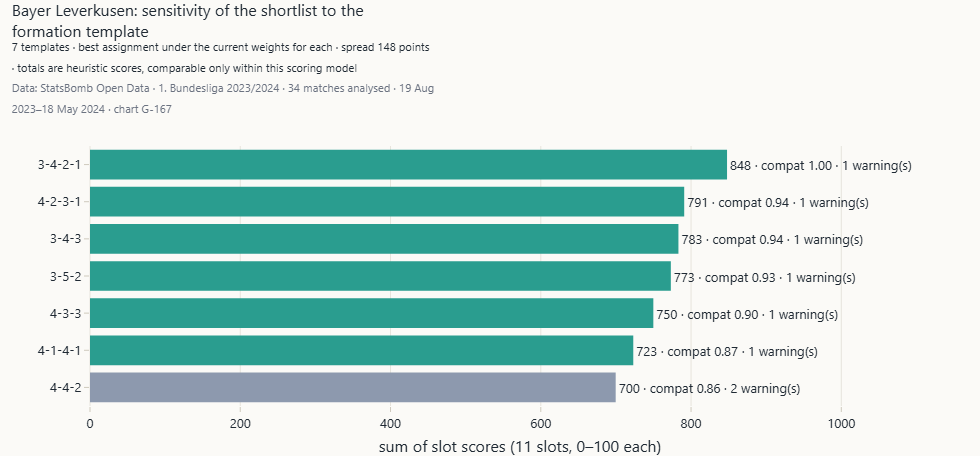

`G-167` Formation sensitivity chart · *Method:* Best total score under each template. · *Caveat:* Heuristic totals, comparable only within this model.

**Interpretation.** Across five weightings between 9 and 11 players stay the same. The slots that change are the ones where the evidence does not separate the candidates.

**Managerial implication.** The tool is most useful as a way to see which slots are genuinely open and what each weighting assumes — not as a single answer.

In [4]:
# Sensitivity: does the shortlist change when the weights change?
import dataclasses
base_ids = set(res.lineup.player_id)
rows = []
for name, w in {"configured": B.config.xi_score_weights,
                "role fit only": {"role_fit": 1, "recent_form": 0, "sample_reliability": 0, "workload_suitability": 0, "lineup_continuity": 0},
                "form-led": {"role_fit": .2, "recent_form": .5, "sample_reliability": .1, "workload_suitability": .1, "lineup_continuity": .1},
                "continuity-led": {"role_fit": .2, "recent_form": .1, "sample_reliability": .1, "workload_suitability": .1, "lineup_continuity": .5},
                "rotation-led": {"role_fit": .3, "recent_form": .1, "sample_reliability": .1, "workload_suitability": .5, "lineup_continuity": 0}}.items():
    r2 = xi.optimize_xi(ctx, p.formation, dataclasses.replace(B.config, xi_score_weights=w))
    ids = set(r2.lineup.player_id)
    rows.append({"weighting": name, "players kept from configured XI": len(ids & base_ids), "total score": round(r2.total_score, 1),
                 "new players": ", ".join(r2.lineup[~r2.lineup.player_id.isin(base_ids)].player_name) or "—"})
sens = pd.DataFrame(rows)
display(sens)
show("G-167", ws, match_id=mid)
interpret(f"Across five weightings between {sens['players kept from configured XI'].min()} and 11 players stay the same. "
          f"The slots that change are the ones where the evidence does not separate the candidates.")
implication("The tool is most useful as a way to see which slots are genuinely open and what each weighting "
            "assumes — not as a single answer.")

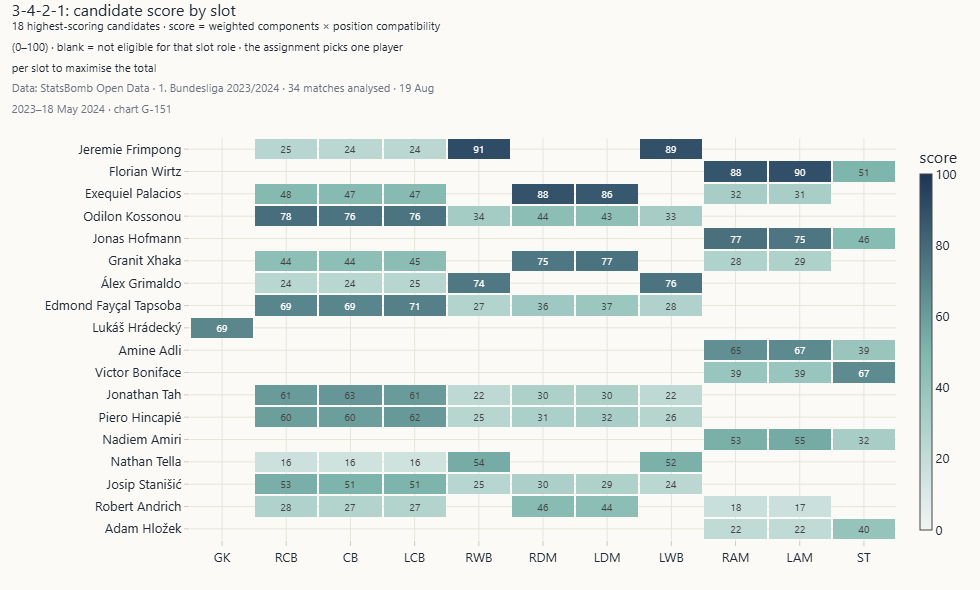

`G-151` Formation slots and role suitability · *Method:* Score per candidate and slot; blank = not eligible.

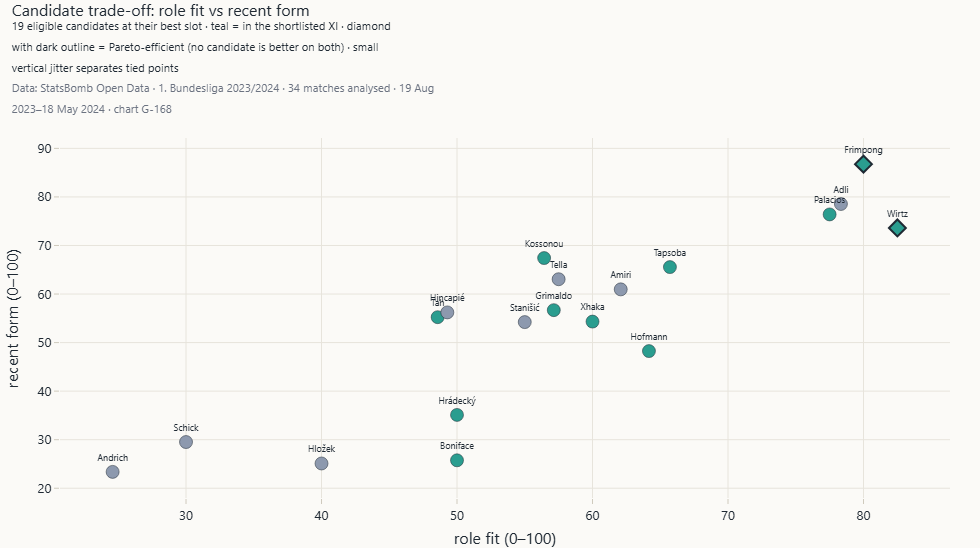

`G-168` Candidate selection frontier · *Method:* Role fit vs recent form with the Pareto front.

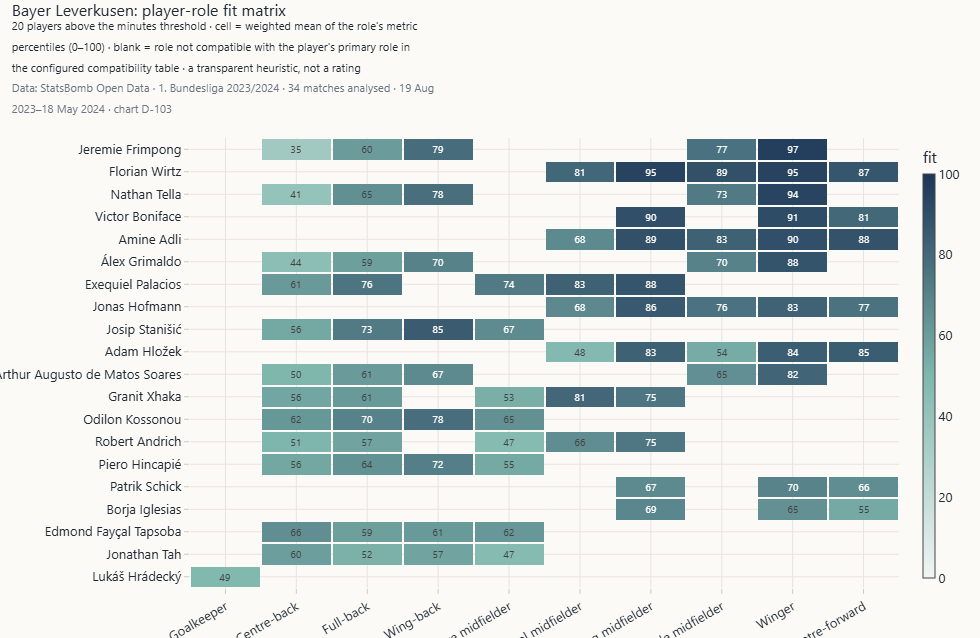

`D-103` Role-fit matrix · *Method:* Weighted role percentiles, masked by position compatibility. · *Caveat:* A transparent heuristic.

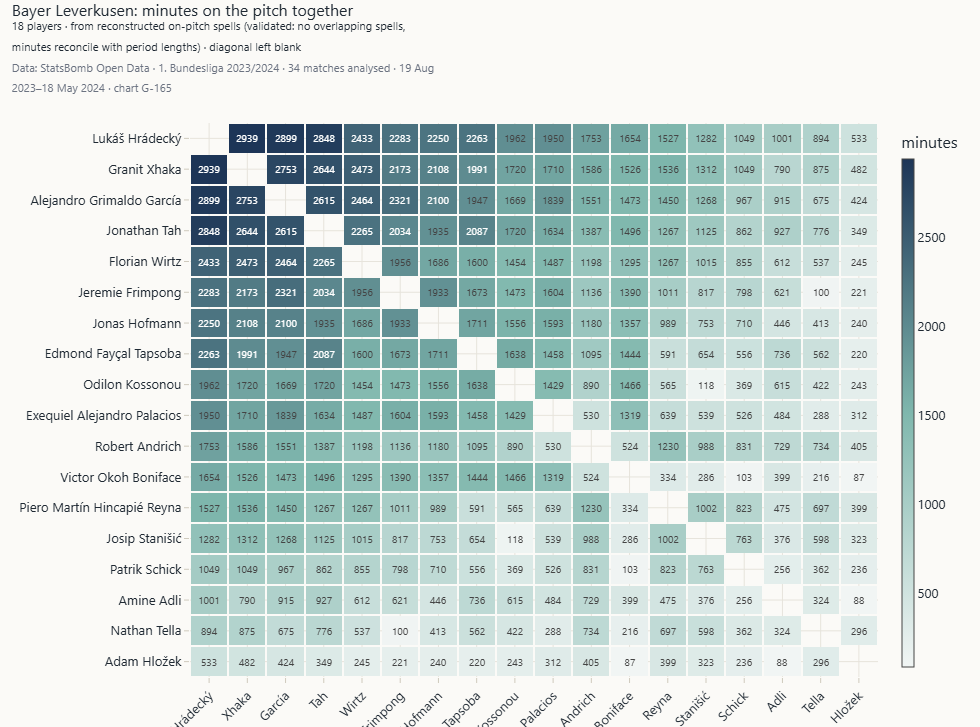

`G-165` Player pairing minutes matrix · *Method:* Shared minutes from reconstructed, validated on-pitch spells.

In [5]:
# Optional, heavier section — set RUN_ADVANCED_GALLERY = True in the setup cell to run it
if RUN_ADVANCED_GALLERY:
    show("G-151", ws, match_id=mid)
    show("G-168", ws, match_id=mid)
    show("D-103", ws)
    show("G-165", ws)

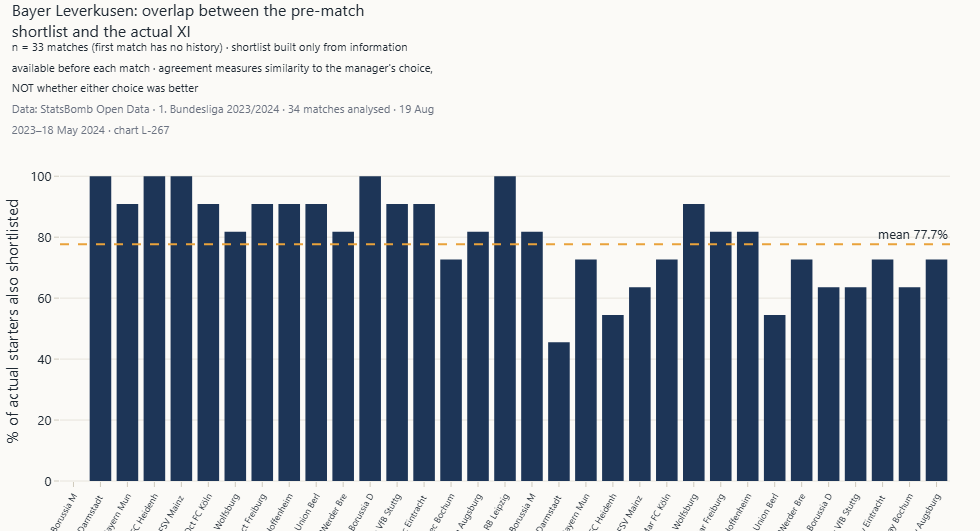

`L-267` Shortlist versus actual XI over the season · *Method:* Share of the actual XI also shortlisted, per match. · *Caveat:* Agreement is similarity, not quality.

**Interpretation.** Over 33 matches the shortlist shares 77.7% of the actual XI on average (minimum 0%, maximum 100%).

**Limitation.** High agreement reflects a stable core that any sensible rule would pick; it is not evidence of decision quality.

In [6]:
# Backtest: rebuild the shortlist before every match from earlier matches only, compare with the actual XI
with timed("XI backtest"):
    ag = ws.xi_agreement()
show("L-267", ws)
interpret(f"Over {len(ag)} matches the shortlist shares {ag.agreement_pct.mean():.1f}% of the actual XI on average "
          f"(minimum {ag.agreement_pct.min():.0f}%, maximum {ag.agreement_pct.max():.0f}%).")
limitation("High agreement reflects a stable core that any sensible rule would pick; it is not evidence of "
           "decision quality.")

## Substitution intelligence

**Research question.** When and in which situations are changes made, who replaces whom, and which bench
options does the evidence shortlist at a given moment?

**Method.** Each substitution is enriched with the score state from the reconstructed goal timeline, the
manpower state from sending-offs, a timing band, the roles of both players and the substitution window under a
configured five-substitutes / three-windows rule. Historical patterns are **descriptive**; scenario shortlists
are **counterfactual simulations**.

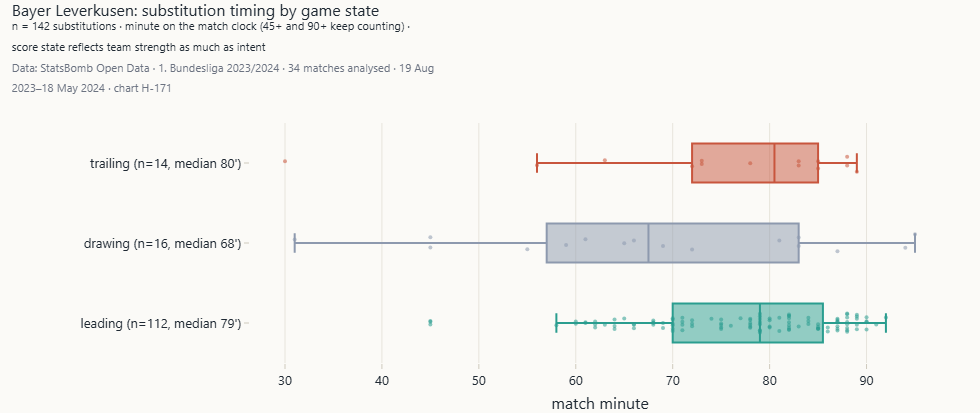

`H-171` Substitution timing by score state · *Method:* Minute distribution per score state. · *Caveat:* Score state reflects team strength as much as intent.

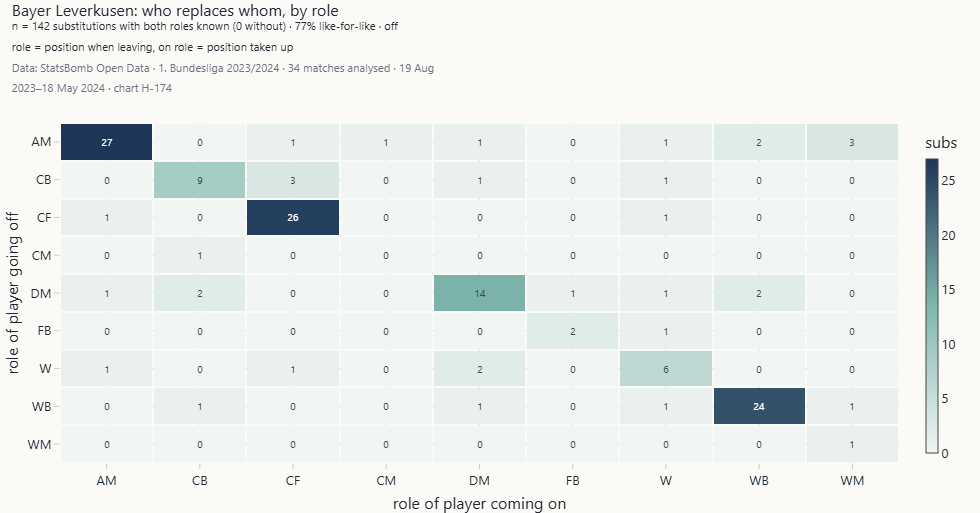

`H-174` Substitution role-matching matrix · *Method:* Off role × on role counts.

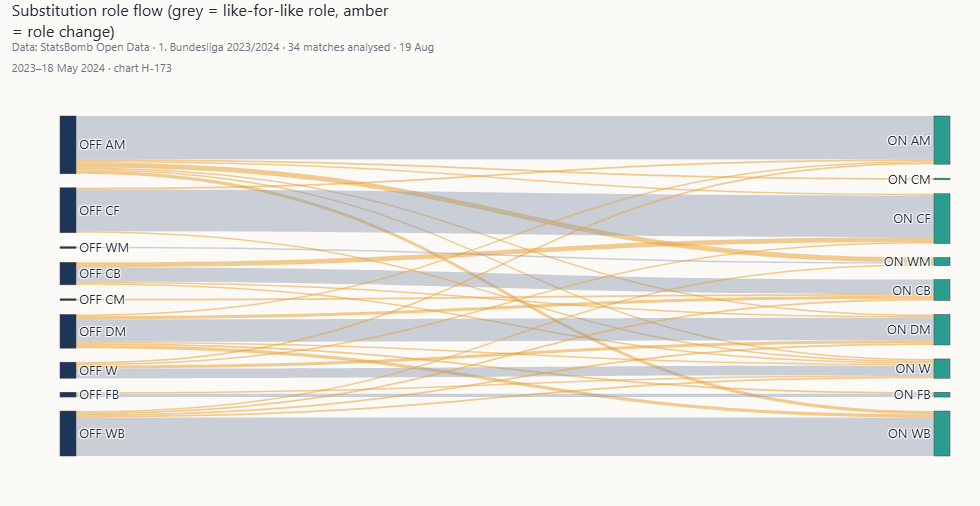

`H-173` Incoming / outgoing role Sankey · *Method:* Role going off → role coming on.

**Interpretation.** Bayer Leverkusen made 142 substitutions (4.18 per match) at a median minute of 79; 79% came while leading and 77% were like-for-like by role. Opponents: median minute 72, 70% while trailing.

**Limitation.** Score state is driven by team strength: a team that usually leads makes most changes while leading whatever its intent. A substitution alone says nothing about injury or fatigue.

In [7]:
S = B.subs; mine = S[S.team_name == FOCUS]; others = S[S.team_name != FOCUS]
show("H-171", ws)
show("H-174", ws)
show("H-173", ws)
interpret(f"{FOCUS} made {len(mine)} substitutions ({len(mine) / len(tm):.2f} per match) at a median minute of {mine.minute.median():.0f}; "
          f"{(mine.game_state == 'leading').mean():.0%} came while leading and {mine.like_for_like.astype(bool).mean():.0%} were "
          f"like-for-like by role. Opponents: median minute {others.minute.median():.0f}, {(others.game_state == 'trailing').mean():.0%} while trailing.")
limitation("Score state is driven by team strength: a team that usually leads makes most changes while leading "
           "whatever its intent. A substitution alone says nothing about injury or fatigue.")

03 Dec 2023: Bayer Leverkusen 1-1 Borussia Dortmund at 65': 0-1 (trailing), 0 substitutions used, 5 remaining · intent 'attack' (Trailing: consider attacking / progression-focused options.)
Rule source: User-configured default (IFAB Law 3 five-substitute option). Verify against the competition's regulations.


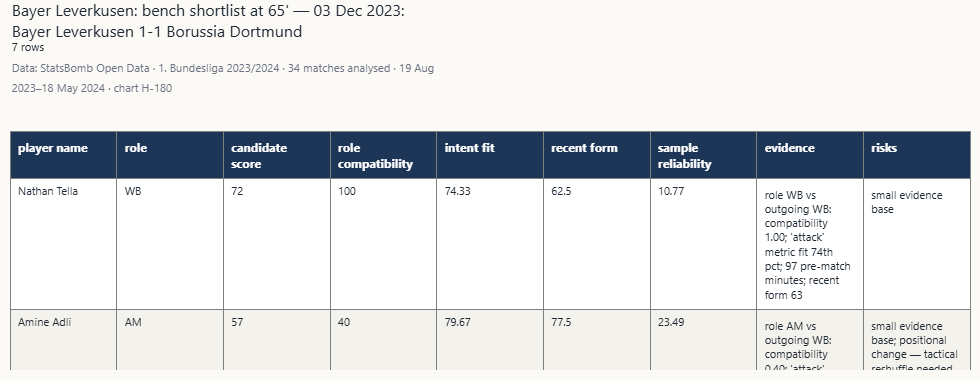

`H-180` Candidate substitute comparison · *Method:* Ranked bench candidates with evidence and risks. · *Caveat:* Candidates are restricted to the match-day bench not yet used at that minute.

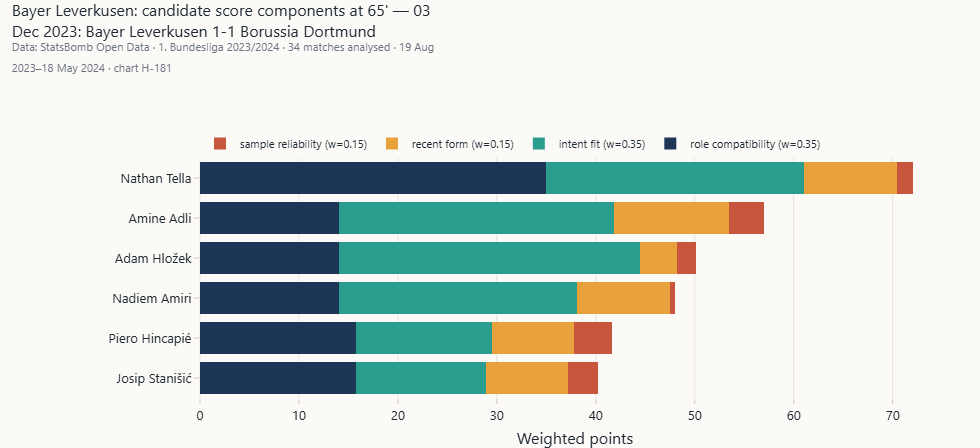

`H-181` Substitution candidate score decomposition · *Method:* Role compatibility, intent fit, recent form, sample reliability.

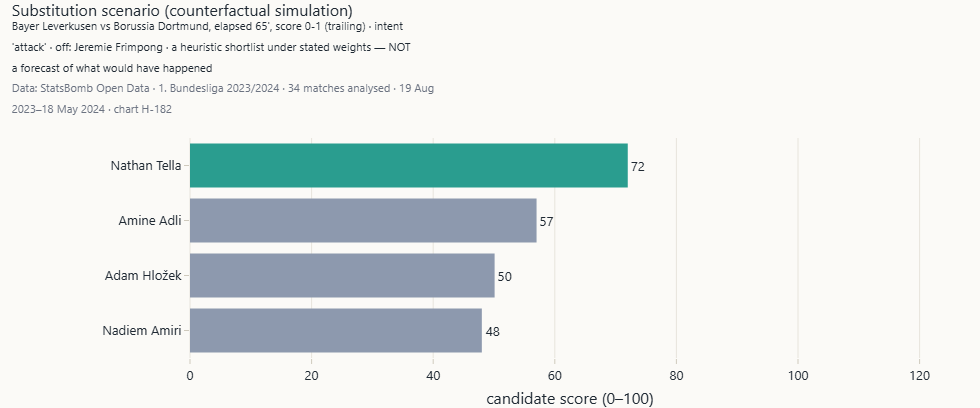

`H-182` Alternative substitution scenario · *Method:* Counterfactual simulation at the selected minute. · *Caveat:* A heuristic shortlist — never a claim about what would have happened.

**Interpretation.** The heuristic would take off Jeremie Frimpong (65 min played this match; role-action rate at 86% of own pre-match baseline (8 role metrics); booked (second-yellow risk)) and shortlist Nathan Tella (score 72; role WB vs outgoing WB: compatibility 1.00; 'attack' metric fit 74th pct; 97 pre-match minutes; recent form 63). Availability: unknown (no injury data in source — not assumed fit).

**Limitation.** A counterfactual shortlist under stated weights. It is not a forecast and cannot say a different change would have altered the result.

In [8]:
from src.analytics import substitution_analysis as sa
minute = 65.0
rec = ws.sub_scenario(FOCUS, mid, minute)
cx = rec["context"]
print(f"{ws.match_label(mid)} at {minute:.0f}': {cx['team_score']}-{cx['opponent_score']} ({cx['game_state']}), "
      f"{cx['subs_used']} substitutions used, {cx['subs_remaining']} remaining · intent '{rec['intent']}' ({rec.get('intent_reason', '')})")
print("Rule source:", cx["rule_source"])
show("H-180", ws, match_id=mid, minute=minute)
show("H-181", ws, match_id=mid, minute=minute)
show("H-182", ws, match_id=mid, minute=minute)
if rec["status"] == "ok":
    on = rec["recommended_on"]
    interpret(f"The heuristic would take off {rec['recommended_off']['player_name']} ({rec['recommended_off']['reasons']}) and shortlist "
              f"{on['player_name']} (score {on['candidate_score']:.0f}; {on['evidence']}). Availability: {on['injury_status']}.")
limitation("A counterfactual shortlist under stated weights. It is not a forecast and cannot say a different "
           "change would have altered the result.")

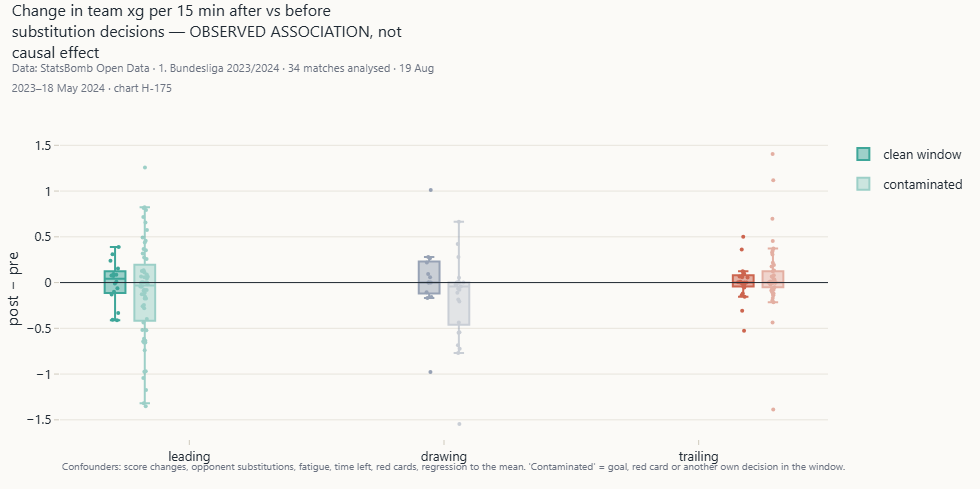

`H-175` Before / after substitution metrics · *Method:* Team xG per 15 minutes in the windows before and after substitution decisions. · *Caveat:* Descriptive only: confounded by score, opponent changes, injuries and regression to the mean.

,game_state,n_decisions,opponent_also_changed_pct,delta_team_shots,delta_team_xg,delta_team_final_third_touches,delta_team_progressive_passes,delta_team_pressures
0,drawing,15,67.000,0.000,-0.067,-3.000,0.000,4.500
1,leading,68,88.000,0.000,-0.007,0.043,0.246,3.000
2,trailing,10,90.000,-0.000,0.191,-10.500,0.000,-0.750


**Interpretation.** Of 93 substitution decisions, 71% have a goal, a red card or another own change inside the before/after window and the opponent also changed in 85%. The median change in team xG per window is -0.010.

**Limitation.** Before/after differences are confounded by score, opponent changes, fatigue and regression to the mean. They are not effects of the substitution.

In [9]:
imp = ws.impact(); imp_t = imp[imp.team_name == FOCUS]
show("H-175", ws)
display(sa.impact_summary(imp_t))
interpret(f"Of {len(imp_t)} substitution decisions, {imp_t.contaminated.mean():.0%} have a goal, a red card or another own "
          f"change inside the before/after window and the opponent also changed in {imp_t.opponent_changed_in_window.mean():.0%}. "
          f"The median change in team xG per window is {imp_t.delta_team_xg.median():+.3f}.")
limitation("Before/after differences are confounded by score, opponent changes, fatigue and regression to the "
           "mean. They are not effects of the substitution.")

,match_id,minute,game_state,actual_off,actual_on,bench_size,rank_actual_on,on_in_top_k,rank_actual_off,off_in_top_k
0,3895052,74,leading,Florian Wirtz,Robert Andrich,9,4.000,False,2,True
1,3895052,88,leading,Jonas Hofmann,Adam Hložek,7,2.000,True,2,True
2,3895052,88,leading,Victor Okoh Boniface,Nadiem Amiri,6,1.000,True,1,True
3,3895060,68,leading,Jeremie Frimpong,Arthur Augusto de Matos Soares,9,1.000,True,3,True
4,3895060,69,leading,Exequiel Alejandro Palacios,Robert Andrich,8,1.000,True,8,False
5,3895060,80,leading,Odilon Kossonou,Josip Stanišić,7,1.000,True,6,False
6,3895060,80,leading,Jonas Hofmann,Adam Hložek,6,3.000,True,5,False
7,3895060,88,leading,Victor Okoh Boniface,Gustavo Adolfo Puerta Molano,5,2.000,True,1,True


**Interpretation.** For 137 non-injury substitutions the player who actually came on was in the heuristic's top three 82.5% of the time; picking three bench players at random would manage about 43%.

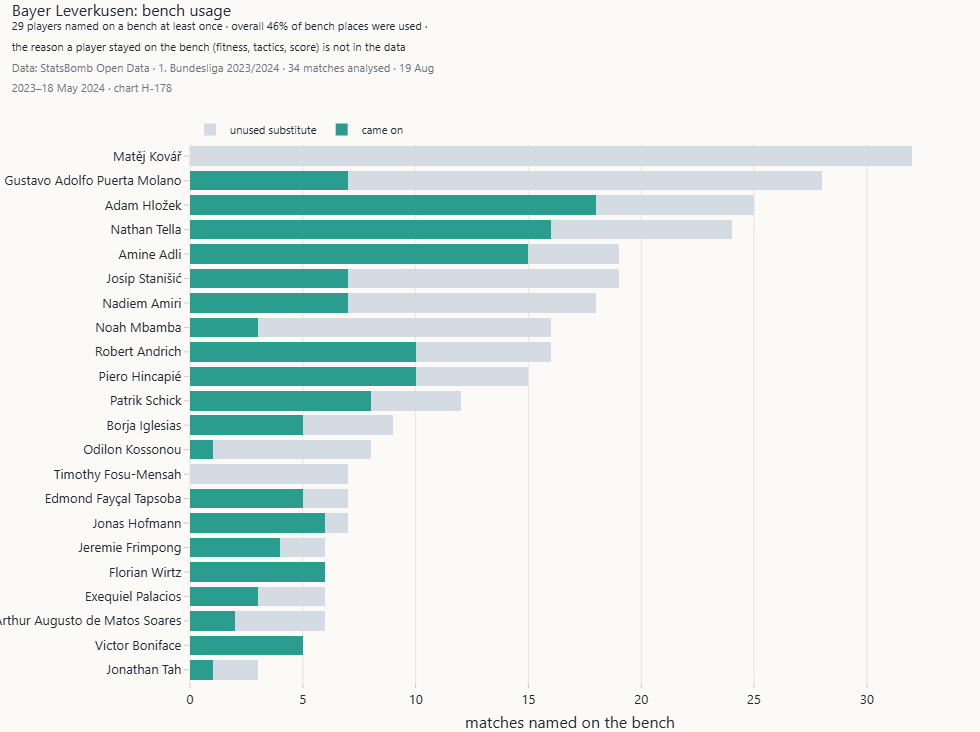

`H-178` Bench usage · *Method:* Times named on the bench, split into used and unused.

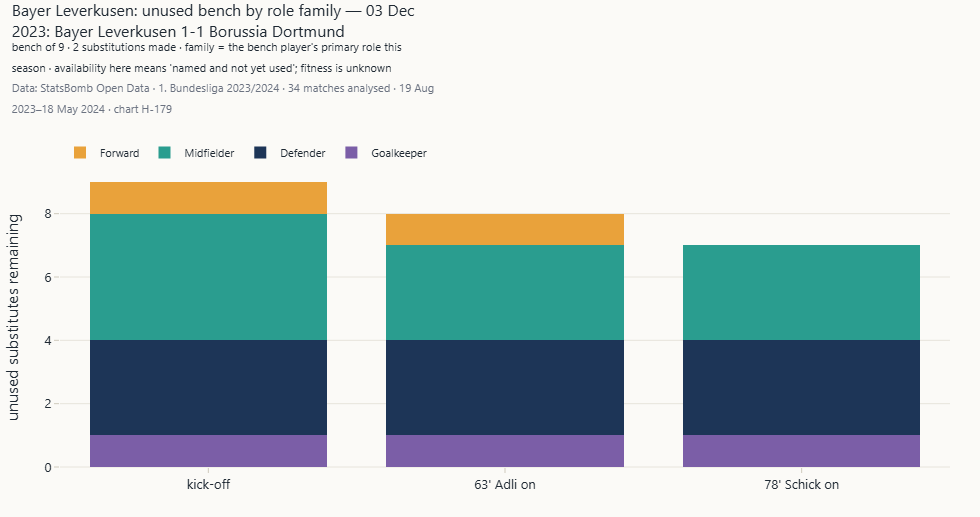

`H-179` Remaining bench availability through a match · *Method:* Unused substitutes after each change. · *Caveat:* Availability = named and not yet used; fitness is unknown.

In [10]:
with timed("substitution backtest"):
    sb = ws.sub_agreement()
rnd = (3 / sb.bench_size.clip(lower=3)).mean()
display(sb.head(8))
interpret(f"For {len(sb)} non-injury substitutions the player who actually came on was in the heuristic's top three "
          f"{sb.on_in_top_k.mean():.1%} of the time; picking three bench players at random would manage about {rnd:.0%}.")
show("H-178", ws)
show("H-179", ws, match_id=mid)